# 01 – Exploratory data analysis

Kaggle *Credit Card Fraud Detection* (`mlg-ulb/creditcardfraud`): card transactions over two
days, with `Time` (seconds since the first transaction), 28 anonymised PCA components
`V1`–`V28`, `Amount` and the target `Class` (1 = fraud).

The goal of this notebook is to find what matters for modelling and validation, not to
build a model. Nothing is trained here.

**What is looked at on which rows.** Sections 1–6 describe the whole dataset (structure,
volumes, label counts). That includes label counts of the later validation and test periods,
which is needed to judge the split itself. Section 7, which ranks features against the
label, uses the **training period only**, so no feature decision is informed by test labels.

Loading, duplicate detection, the time-based split and the hour-of-day feature come from
`src/fraud` and are unit-tested there. Run `make data` first, then `make notebook`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

from fraud.config import AMOUNT_COLUMN, PCA_COLUMNS, TARGET_COLUMN, TIME_COLUMN
from fraud.data import duplicate_group_id, duplicate_mask, load_raw, split_summary, time_based_split
from fraud.features import class_separation, elapsed_hour, hour_of_day
from fraud.plotting import (
    CLASS_COLORS,
    CLASS_LABELS,
    FRAUD_COLOR,
    NEUTRAL_COLOR,
    save_figure,
    set_style,
)

set_style()
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 40)

df = load_raw()
is_fraud = df[TARGET_COLUMN] == 1

## 1. Overview

In [2]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Dtypes: {df.dtypes.astype(str).value_counts().to_dict()}")
print(f"Missing values: {int(df.isna().sum().sum())}")
print(f"Time span: {df[TIME_COLUMN].max() / 3600:.1f} hours")
df.head(3)

Shape: 284,807 rows x 31 columns
Dtypes: {'float64': 30, 'int64': 1}
Missing values: 0
Time span: 48.0 hours


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


In [3]:
df.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

,mean,std,min,50%,max
Time,94813.86,47488.15,0.00,84692.00,172792.00
V1,0.00,1.96,-56.41,0.02,2.45
V2,0.00,1.65,-72.72,0.07,22.06
V3,-0.00,1.52,-48.33,0.18,9.38
V4,0.00,1.42,-5.68,-0.02,16.88
V5,0.00,1.38,-113.74,-0.05,34.80
V6,0.00,1.33,-26.16,-0.27,73.30
V7,-0.00,1.24,-43.56,0.04,120.59
V8,0.00,1.19,-73.22,0.02,20.01
V9,-0.00,1.10,-13.43,-0.05,15.59


- 284,807 rows and 31 columns, all numeric, **no missing values**, so no imputation is needed.
- `V1`–`V28` are centred on zero with decreasing spread (std from about 1.96 for `V1` down to
  0.33 for `V28`), as expected from PCA components ordered by explained variance. Their
  extremes are far out (for example `V2` reaches −72), so the tails are heavy.
- `Amount` is strongly right-skewed: median 22, mean 88, maximum 25,691.
- `Time` runs from 0 to 172,792 seconds, i.e. two full days.

## 2. Class balance

In [4]:
class_counts = df[TARGET_COLUMN].value_counts().sort_index()
balance = pd.DataFrame(
    {
        "class": [CLASS_LABELS[label] for label in class_counts.index],
        "transactions": class_counts.to_numpy(),
        "share_pct": (100 * class_counts / len(df)).round(3).to_numpy(),
    }
)
display(balance)

always_legit_accuracy = (~is_fraud).mean()
print(f"Accuracy of always predicting 'not fraud': {always_legit_accuracy:.3%}")
print(f"Imbalance ratio: 1 fraud per {class_counts[0] / class_counts[1]:.0f} legitimate")

,class,transactions,share_pct
0,Legitimate,284315,99.827
1,Fraud,492,0.173


Accuracy of always predicting 'not fraud': 99.827%
Imbalance ratio: 1 fraud per 578 legitimate


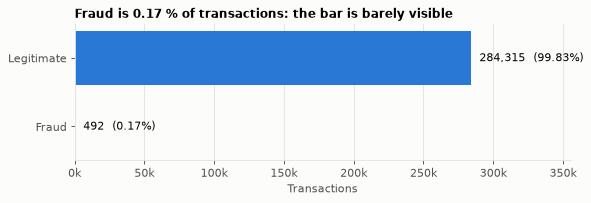

In [5]:
fig, ax = plt.subplots(figsize=(8, 2.2))
labels = [CLASS_LABELS[label] for label in class_counts.index]
ax.barh(labels, class_counts, color=[CLASS_COLORS[label] for label in class_counts.index])
for position, count in enumerate(class_counts):
    ax.text(count, position, f"  {count:,}  ({count / len(df):.2%})", va="center")
ax.invert_yaxis()
ax.set_xlim(0, class_counts.max() * 1.25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1000:.0f}k"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Transactions")
ax.set_title("Fraud is 0.17 % of transactions: the bar is barely visible")
save_figure(fig, "eda_class_balance")
plt.show()

Only **492 of 284,807** transactions (0.173 %) are fraud: one fraud for every 578 legitimate
transactions.

**Why accuracy is misleading.** A "model" that always answers *not fraud* is right 99.827 % of
the time while catching zero fraud. Any real model has to be compared against that number,
and improvements that matter (catching more of the 492) move accuracy only in the third
decimal. Accuracy also treats a missed fraud and a false alarm as equally bad, which they are
not. The project therefore uses **PR-AUC** as the primary metric, with precision and recall at
a threshold chosen from business cost. ROC-AUC is reported too, but it is also flattering
under this much imbalance because the false positive rate is divided by a huge number of
negatives.

## 3. Duplicates

Two definitions: rows identical in **all 31 columns** (same second, same features, same
amount, same label), and rows identical in everything **except `Time`** (the same feature
vector seen again at another moment). The counts below are *redundant* rows, i.e. the first
occurrence of each group is not counted.

In [6]:
exact_dup = duplicate_mask(df)
feature_dup = duplicate_mask(df, ignore=[TIME_COLUMN])

duplicates = pd.DataFrame(
    {
        "redundant_rows": [exact_dup.sum(), feature_dup.sum()],
        "share_of_rows_pct": [100 * exact_dup.mean(), 100 * feature_dup.mean()],
        "of_which_fraud": [(exact_dup & is_fraud).sum(), (feature_dup & is_fraud).sum()],
        "share_of_all_fraud_pct": [
            100 * (exact_dup & is_fraud).sum() / is_fraud.sum(),
            100 * (feature_dup & is_fraud).sum() / is_fraud.sum(),
        ],
    },
    index=["exact (all columns)", "ignoring Time"],
).round(2)
duplicates

,redundant_rows,share_of_rows_pct,of_which_fraud,share_of_all_fraud_pct
exact (all columns),1081,0.38,19,3.86
ignoring Time,9144,3.21,19,3.86


In [7]:
# Groups of rows that share the same features, amount and label (Time may differ).
group = duplicate_group_id(df, ignore=[TIME_COLUMN])
group_size = group.map(group.value_counts())
repeated = df[group_size > 1].assign(group=group)
group_stats = repeated.groupby("group").agg(
    rows=(TIME_COLUMN, "size"),
    time_span_s=(TIME_COLUMN, lambda time: time.max() - time.min()),
    labels=(TARGET_COLUMN, "nunique"),
    fraud=(TARGET_COLUMN, "max"),
    amount=(AMOUNT_COLUMN, "first"),
)
fraud_groups = group_stats[group_stats["fraud"] == 1]

print(f"Groups with repeated features: {len(group_stats):,} covering {len(repeated):,} rows")
print(f"Largest group: {group_stats['rows'].max()} rows")
print(f"Groups with conflicting labels: {(group_stats['labels'] > 1).sum()}")
print(f"Median amount of a repeated group: {group_stats['amount'].median():.2f}")
print(f"Median time between first and last repeat: {group_stats['time_span_s'].median():,.0f} s")
print(
    f"Fraud groups: {len(fraud_groups)} covering {fraud_groups['rows'].sum()} fraud rows; "
    f"largest time span within a fraud group: {fraud_groups['time_span_s'].max():.0f} s"
)

Groups with repeated features: 5,149 covering 14,293 rows
Largest group: 77 rows
Groups with conflicting labels: 0
Median amount of a repeated group: 1.98
Median time between first and last repeat: 10,956 s
Fraud groups: 13 covering 32 fraud rows; largest time span within a fraud group: 0 s


In [8]:
# How do duplicates interact with the time-based split (previewed in section 6)?
splits = time_based_split(df)
split_of = pd.Series("", index=df.index)
for name, part in splits.items():
    split_of.loc[part.index] = name

rows = {}
for later, earlier in [("train", []), ("val", ["train"]), ("test", ["train", "val"])]:
    in_split = split_of == later
    twins = in_split & group.isin(set(group[split_of.isin(earlier)]))
    rows[later] = {
        "rows": in_split.sum(),
        "exact_duplicates": (exact_dup & in_split).sum(),
        "exact_duplicates_fraud": (exact_dup & in_split & is_fraud).sum(),
        "rows_with_twin_in_earlier_split": twins.sum(),
        "share_with_twin_pct": round(100 * twins.sum() / in_split.sum(), 2),
        "twins_fraud": (twins & is_fraud).sum(),
    }
pd.DataFrame.from_dict(rows, orient="index")

,rows,exact_duplicates,exact_duplicates_fraud,rows_with_twin_in_earlier_split,share_with_twin_pct,twins_fraud
train,199364,716,18,0,0.00,0
val,42719,182,1,824,1.93,0
test,42724,183,0,1431,3.35,0


**What the numbers say**

- **1,081 exact duplicates** (0.38 % of rows), **19 of them fraud**. That is 3.9 % of all fraud
  cases, ten times the share among legitimate rows, so duplicates are concentrated in the
  class we care about.
- Ignoring `Time` there are **9,144 redundant rows** in 5,149 groups, but the fraud count stays
  at 19: **every fraud duplicate is an exact, same-second duplicate**. No fraud feature vector
  repeats at a different time.
- The repeats at different times are all legitimate, mostly tiny amounts (median about 2,
  largest group 77 rows spread over about half a day). With 28 PCA components matching to full
  precision these are the same card doing the same thing again, which looks like recurring
  or automated micro-payments. No group has conflicting labels.

**What this means for leakage**

- The split cuts on `Time` values, so rows with the same timestamp always land in the same
  split. **Exact duplicates can therefore never straddle train/validation/test.** The classic
  problem (the same fraud row in train and test) would appear with a *random* split, not with
  ours.
- Repeats at different times do cross the boundaries: 824 validation rows (1.9 %) and 1,431
  test rows (3.3 %) have an identical feature vector earlier in time. All are legitimate. This
  is not leakage in the strict sense, because the earlier transaction really is known at
  prediction time and production traffic would look the same. It does make those negatives
  trivially easy, so it flatters the false-positive side a little and says nothing about
  fraud recall.
- The real risks are inside the training data: with random k-fold cross-validation, copies of
  one fraud row fall into different folds and the fold score becomes optimistic; SMOTE-type
  methods pick nearest neighbours at distance zero and synthesise more copies of the same
  point; and with only about 50 fraud cases per evaluation split, one duplicated case counts
  twice in recall.

**Recommendation for Phase 2**

1. **Drop exact duplicates (all 31 columns, keep the first) once, before splitting.** It is a
   label-free, stateless row operation, so doing it before the split cannot leak anything,
   and because exact duplicates share a timestamp the result is the same as deduplicating
   each split separately. It removes 1,081 rows and leaves 473 fraud cases.
2. **Keep the rows that repeat only at a different time.** They are distinct transactions,
   they are what the model would see in production, and removing 8,063 legitimate rows would
   change the class prior and the volume pattern for no benefit.
3. **Use time-ordered (or grouped by `duplicate_group_id`) folds for any cross-validation
   inside the training set**, never plain shuffled k-fold.
4. As a sensitivity check, report the final test metrics once with and once without the
   deduplication. Test has no fraud duplicates, so the fraud side should not move.

The uncertain part is whether same-second identical fraud rows are a recording artefact or
real repeated charges (some are 1.00 amounts repeated up to six times, which looks like card
testing). If they are real, each one costs money and dropping them slightly understates fraud
volume. Dropping is still the safer default for honest validation; the cost model in Phase 4
can be run on the raw test set to check.

## 4. Amount by class

In [9]:
def amount_stats(amount: pd.Series) -> pd.Series:
    return pd.Series(
        {
            "transactions": len(amount),
            "median": amount.median(),
            "mean": amount.mean(),
            "p90": amount.quantile(0.90),
            "p99": amount.quantile(0.99),
            "max": amount.max(),
            "zero_amount": (amount == 0).sum(),
            "zero_amount_pct": 100 * (amount == 0).mean(),
            "total": amount.sum(),
        }
    )


amount_table = df.groupby(TARGET_COLUMN)[AMOUNT_COLUMN].apply(amount_stats).unstack()
amount_table.index = [CLASS_LABELS[label] for label in amount_table.index]
amount_table.round(2)

,transactions,median,mean,p90,p99,max,zero_amount,zero_amount_pct,total
Legitimate,284315.0,22.00,88.29,202.72,1016.97,25691.16,1798.0,0.63,25102462.04
Fraud,492.0,9.25,122.21,346.75,1357.43,2125.87,27.0,5.49,60127.97


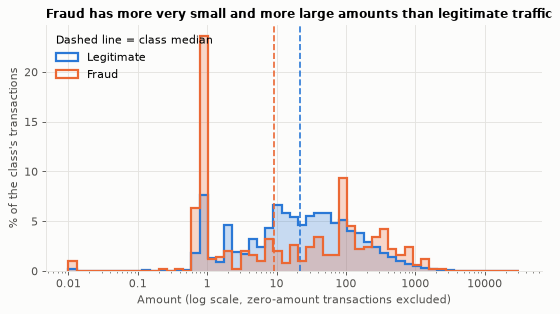

In [10]:
positive = df[AMOUNT_COLUMN] > 0
bins = np.logspace(np.log10(df.loc[positive, AMOUNT_COLUMN].min()), 4.5, 56)

fig, ax = plt.subplots(figsize=(8, 4))
for label in (0, 1):
    in_class = df[TARGET_COLUMN] == label
    amounts = df.loc[in_class & positive, AMOUNT_COLUMN]
    weights = np.full(len(amounts), 100 / in_class.sum())
    shared = {"bins": bins, "weights": weights, "color": CLASS_COLORS[label]}
    ax.hist(amounts, histtype="stepfilled", alpha=0.25, **shared)
    ax.hist(amounts, histtype="step", linewidth=2, label=CLASS_LABELS[label], **shared)
    median = df.loc[in_class, AMOUNT_COLUMN].median()
    ax.axvline(median, color=CLASS_COLORS[label], linestyle="--", linewidth=1.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
ax.set_xlabel("Amount (log scale, zero-amount transactions excluded)")
ax.set_ylabel("% of the class's transactions")
ax.set_title("Fraud has more very small and more large amounts than legitimate traffic")
ax.legend(title="Dashed line = class median", loc="upper left", alignment="left")
save_figure(fig, "eda_amount_by_class")
plt.show()

- Both classes are heavily right-skewed, so `Amount` needs a **log transform** (`log1p`, since
  zeros exist) before it goes into a scaled linear model. Tree models do not care, but the
  transform does not hurt them.
- The **median fraud is smaller** (9.25 vs 22.00) but the **mean is larger** (122 vs 88): fraud
  is bimodal, with a spike of very small amounts around 1 (typical for card testing) and a
  heavier share of amounts in the hundreds. The largest fraud is 2,126, while legitimate
  amounts reach 25,691.
- **Zero-amount transactions** are 0.63 % of legitimate rows but **5.5 % of fraud** (27 cases).
  Under the cost model of the plan, a missed zero-amount fraud costs nothing, while flagging
  it costs a review. That is worth remembering when the threshold is chosen in Phase 4.
- All fraud in the two days adds up to about 60,128 in amount. That is the "no model" cost the
  later savings figure is measured against.

## 5. Time

`Time` is seconds since the first transaction, covering two days. `hour_of_day` assumes the
recording starts at midnight, which the dataset does not state; the volume curve below (a
deep trough a few hours after the start, on both days) makes that plausible.

In [11]:
hourly = df.assign(hour=hour_of_day(df[TIME_COLUMN])).groupby("hour")[TARGET_COLUMN]
by_hour = hourly.agg(transactions="size", fraud="sum")
by_hour["fraud_rate_pct"] = 100 * by_hour["fraud"] / by_hour["transactions"]

night = hour_of_day(df[TIME_COLUMN]).between(1, 5)
print(f"Hours 1-5: {night.mean():.1%} of transactions, {night[is_fraud].mean():.1%} of fraud")
print(f"Fraud rate, hours 1-5: {is_fraud[night].mean():.2%}; other: {is_fraud[~night].mean():.2%}")
by_hour.T.round(2)

Hours 1-5: 5.7% of transactions, 24.0% of fraud
Fraud rate, hours 1-5: 0.73%; other: 0.14%


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
transactions,7695.00,4220.00,3328.00,3492.00,2209.00,2990.00,4101.00,7243.00,10276.00,15838.0,16598.00,16856.00,15420.00,15365.00,16570.00,16461.00,16453.00,16166.00,17039.00,15649.00,16756.00,17703.00,15441.00,10938.00
fraud,6.00,10.00,57.00,17.00,23.00,11.00,9.00,23.00,9.00,16.0,8.00,53.00,17.00,17.00,23.00,26.00,22.00,29.00,33.00,19.00,18.00,16.00,9.00,21.00
fraud_rate_pct,0.08,0.24,1.71,0.49,1.04,0.37,0.22,0.32,0.09,0.1,0.05,0.31,0.11,0.11,0.14,0.16,0.13,0.18,0.19,0.12,0.11,0.09,0.06,0.19


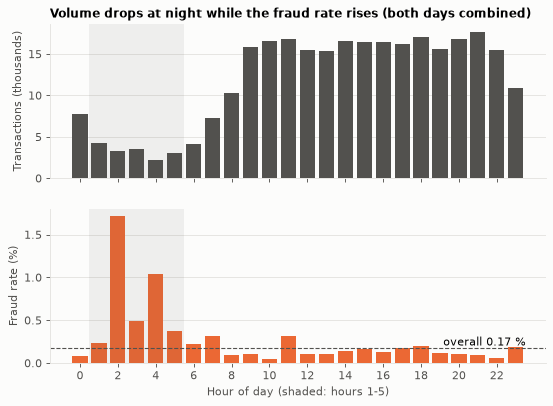

In [12]:
overall_rate_pct = 100 * is_fraud.mean()

fig, (ax_volume, ax_rate) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
ax_volume.bar(by_hour.index, by_hour["transactions"] / 1000, color=NEUTRAL_COLOR, width=0.8)
ax_volume.set_ylabel("Transactions (thousands)")
ax_volume.set_title("Volume drops at night while the fraud rate rises (both days combined)")

ax_rate.bar(by_hour.index, by_hour["fraud_rate_pct"], color=FRAUD_COLOR, width=0.8)
ax_rate.axhline(overall_rate_pct, color=NEUTRAL_COLOR, linestyle="--", linewidth=1)
ax_rate.text(23.5, overall_rate_pct, f"overall {overall_rate_pct:.2f} %", ha="right", va="bottom")
ax_rate.set_ylabel("Fraud rate (%)")
ax_rate.set_xlabel("Hour of day (shaded: hours 1-5)")
ax_rate.set_xticks(range(0, 24, 2))
for ax in (ax_volume, ax_rate):
    ax.axvspan(0.5, 5.5, color=NEUTRAL_COLOR, alpha=0.08, linewidth=0)
    ax.grid(axis="x", visible=False)
save_figure(fig, "eda_time_by_hour")
plt.show()

- Volume follows a clear **day/night cycle**: about 15–18 thousand transactions per hour of
  day from 9 to 22, falling to 2–4 thousand in hours 1–6.
- Fraud does not slow down at night the way legitimate traffic does. Hours 1–5 hold 5.7 % of
  transactions but **24 % of fraud**; the fraud rate there is 0.73 % against 0.14 % in the rest
  of the day, roughly five times higher.
- The hourly fraud counts are small and bursty (see the next section: one hour has 43 cases
  and another 36, probably a few compromised cards used repeatedly), so the exact shape of the hourly
  curve should not be over-read. The night effect itself is visible on both nights.
- Raw `Time` is a poor feature: it is a running index, and under a time-based split every
  validation and test value lies outside the range seen in training. **Hour of day** is the
  useful, repeatable part.

## 6. Time-based split preview

The plan (section 5) trains on the earliest 70 % of transactions, validates on the next 15 %
and tests on the last 15 %, with no shuffling.

In [13]:
def format_summary(summary: pd.DataFrame) -> pd.DataFrame:
    return summary.assign(
        share_pct=(100 * summary["share"]).round(1),
        fraud_rate_pct=(100 * summary["fraud_rate"]).round(3),
        start_hour=(summary["time_start"] / 3600).round(1),
        end_hour=(summary["time_end"] / 3600).round(1),
    )[["rows", "share_pct", "fraud", "fraud_rate_pct", "start_hour", "end_hour"]]


summary = split_summary(splits)
print("All rows")
display(format_summary(summary))

print("After dropping exact duplicates (recommendation from section 3)")
display(format_summary(split_summary(time_based_split(df[~exact_dup]))))

All rows


,rows,share_pct,fraud,fraud_rate_pct,start_hour,end_hour
split,,,,,,
train,199364,70.0,384,0.193,0.0,36.9
val,42719,15.0,56,0.131,36.9,42.0
test,42724,15.0,52,0.122,42.0,48.0


After dropping exact duplicates (recommendation from section 3)


,rows,share_pct,fraud,fraud_rate_pct,start_hour,end_hour
split,,,,,,
train,198607,70.0,366,0.184,0.0,36.9
val,42558,15.0,55,0.129,36.9,42.0
test,42561,15.0,52,0.122,42.0,48.0


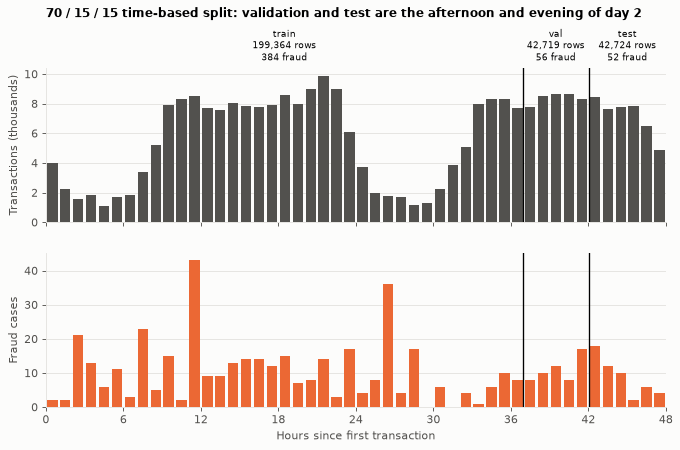

In [14]:
per_hour = df.assign(hour=elapsed_hour(df[TIME_COLUMN])).groupby("hour")[TARGET_COLUMN]
per_hour = per_hour.agg(transactions="size", fraud="sum")
boundaries = [summary.loc[name, "time_start"] / 3600 for name in ("val", "test")]
edges = [0, *boundaries, 48]

fig, (ax_volume, ax_fraud) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
thousands = per_hour["transactions"] / 1000
ax_volume.bar(per_hour.index + 0.5, thousands, color=NEUTRAL_COLOR, width=0.8)
ax_volume.set_ylabel("Transactions (thousands)")
ax_fraud.bar(per_hour.index + 0.5, per_hour["fraud"], color=FRAUD_COLOR, width=0.8)
ax_fraud.set_ylabel("Fraud cases")
ax_fraud.set_xlabel("Hours since first transaction")
ax_fraud.set_xticks(range(0, 49, 6))
ax_fraud.set_xlim(0, 48)

for ax in (ax_volume, ax_fraud):
    ax.grid(axis="x", visible=False)
    for boundary in boundaries:
        ax.axvline(boundary, color="black", linewidth=1.2)
for name, left, right in zip(summary.index, edges[:-1], edges[1:], strict=True):
    label = f"{name}\n{summary.loc[name, 'rows']:,} rows\n{summary.loc[name, 'fraud']} fraud"
    ax_volume.text(
        (left + right) / 2,
        1.03,
        label,
        transform=ax_volume.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=8.5,
    )
ax_volume.set_title(
    "70 / 15 / 15 time-based split: validation and test are the afternoon and evening of day 2",
    pad=46,
)
save_figure(fig, "eda_time_split")
plt.show()

In [15]:
# How precise can recall be with this few fraud cases? Binomial 95 % half-width at recall 0.8.
recall = 0.8
precision_of_recall = pd.DataFrame(
    {
        "fraud_cases": summary["fraud"],
        "recall_step_per_case_pct": (100 / summary["fraud"]).round(1),
        "recall_ci95_half_width_pct": (
            100 * 1.96 * np.sqrt(recall * (1 - recall) / summary["fraud"])
        ).round(1),
    }
)
precision_of_recall

,fraud_cases,recall_step_per_case_pct,recall_ci95_half_width_pct
split,,,
train,384,0.3,4.0
val,56,1.8,10.5
test,52,1.9,10.9


- The split gives **384 / 56 / 52 fraud cases** in train / validation / test. Because the
  boundaries are cut by row count while traffic is dense during the day, the 70 % training
  part covers the first 37 hours, and validation and test are each only about **5–6 hours**:
  validation is day-2 afternoon (roughly hours 13–18), test is day-2 evening (18–24).
- **Validation and test contain no night hours.** Both nights lie in the training period, so
  the fraud rate drops from 0.19 % in train to 0.13 % and 0.12 %, and whatever the model learns
  about night-time fraud cannot be checked on the evaluation splits. This is a limitation of
  a two-day dataset, not something a different split fraction fixes cheaply.
- With about 50 fraud cases, **one case moves recall by almost 2 percentage points**, and a
  recall of 0.80 has a 95 % interval of roughly ±11 points. Differences of a few points in
  recall or PR-AUC between two configurations are within noise.
- Consequences for later phases: report **bootstrap confidence intervals** for PR-AUC (and
  for cost) on validation and test, resampling transactions with the fraud cases stratified;
  compare configurations with paired bootstrap on the same resamples rather than by point
  estimates; and choose between close candidates with time-ordered cross-validation on the
  training set, where there are 384 fraud cases, not on the 56 validation cases alone.
- Fraud arrives in bursts (two hours have 43 and 36 cases, most have fewer than 15), so the cases are
  not independent. Real uncertainty is therefore somewhat larger than the binomial figure.

## 7. Features

This section uses the **training period only**. Each feature is scored on its own with a
rank-based measure: the ROC-AUC obtained by using the raw feature value as a score
(equivalent to the Mann-Whitney U statistic). `separation = |2·AUC − 1|` is 0 for no
separation and 1 for perfect separation, in either direction. No model is fitted.

In [16]:
train = splits["train"].assign(hour=hour_of_day(splits["train"][TIME_COLUMN]))
feature_names = [*PCA_COLUMNS, AMOUNT_COLUMN, "hour"]

separation = class_separation(train, feature_names)
separation["pearson_with_class"] = train[feature_names].corrwith(train[TARGET_COLUMN])
separation.head(10).round(3)

,median_legit,median_fraud,median_diff_std,auc,separation,pearson_with_class
feature,,,,,,
V14,0.077,-6.980,-7.261,0.048,0.903,-0.326
V12,0.115,-6.470,-6.019,0.057,0.887,-0.277
V4,0.074,4.324,3.037,0.940,0.880,0.147
V3,0.495,-5.153,-3.901,0.077,0.845,-0.244
V10,-0.099,-5.053,-4.533,0.079,0.842,-0.256
V11,0.064,3.974,3.756,0.919,0.838,0.171
V2,0.080,2.963,1.778,0.879,0.758,0.114
V16,0.063,-4.333,-4.962,0.138,0.725,-0.234
V7,-0.009,-3.878,-3.176,0.151,0.699,-0.238


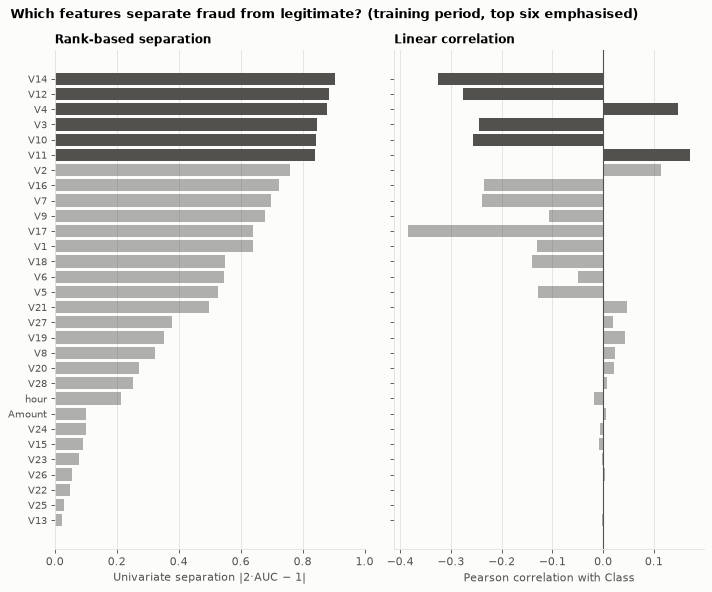

In [17]:
ordered = separation.iloc[::-1]
top_features = list(separation.index[:6])
alphas = [1.0 if feature in top_features else 0.45 for feature in ordered.index]

fig, (ax_sep, ax_corr) = plt.subplots(1, 2, figsize=(9, 7.5), sharey=True)
ax_sep.barh(ordered.index, ordered["separation"], color=NEUTRAL_COLOR)
for bar, alpha in zip(ax_sep.patches, alphas, strict=True):
    bar.set_alpha(alpha)
ax_sep.set_xlim(0, 1)
ax_sep.set_xlabel("Univariate separation |2·AUC − 1|")
ax_sep.set_title("Rank-based separation")

ax_corr.barh(ordered.index, ordered["pearson_with_class"], color=NEUTRAL_COLOR)
for bar, alpha in zip(ax_corr.patches, alphas, strict=True):
    bar.set_alpha(alpha)
ax_corr.axvline(0, color=NEUTRAL_COLOR, linewidth=1)
ax_corr.set_xlabel("Pearson correlation with Class")
ax_corr.set_title("Linear correlation")

for ax in (ax_sep, ax_corr):
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=9)
fig.suptitle(
    "Which features separate fraud from legitimate? (training period, top six emphasised)",
    x=0.02,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
save_figure(fig, "eda_feature_separation")
plt.show()

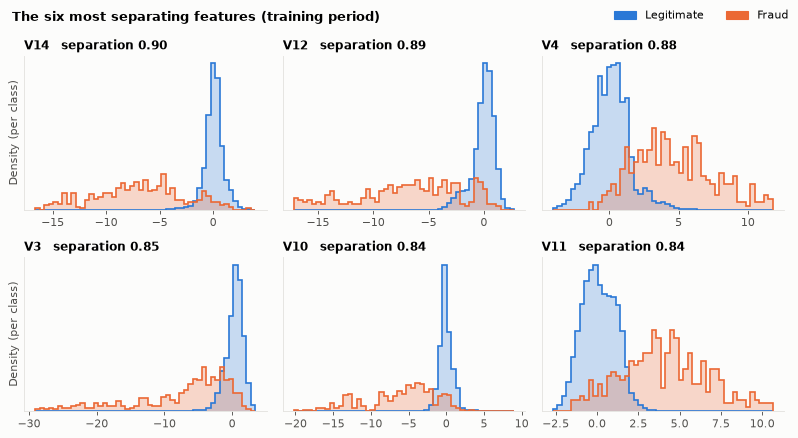

In [18]:
train_fraud = train[TARGET_COLUMN] == 1

fig, axes = plt.subplots(2, 3, figsize=(10, 5.5))
for ax, feature in zip(axes.flat, top_features, strict=True):
    low = min(train[feature].quantile(0.001), train.loc[train_fraud, feature].quantile(0.02))
    high = max(train[feature].quantile(0.999), train.loc[train_fraud, feature].quantile(0.98))
    bins = np.linspace(low, high, 50)
    for label in (0, 1):
        values = train.loc[train[TARGET_COLUMN] == label, feature]
        shared = {"bins": bins, "density": True, "color": CLASS_COLORS[label]}
        ax.hist(values, histtype="stepfilled", alpha=0.25, **shared)
        ax.hist(values, histtype="step", linewidth=1.5, **shared)
    ax.set_title(f"{feature}   separation {separation.loc[feature, 'separation']:.2f}")
    ax.set_yticks([])
    ax.grid(visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Density (per class)")
handles = [Patch(color=CLASS_COLORS[label], label=CLASS_LABELS[label]) for label in (0, 1)]
fig.legend(handles=handles, loc="upper right", ncols=2)
fig.suptitle(
    "The six most separating features (training period)", x=0.02, ha="left", fontweight="bold"
)
fig.tight_layout()
save_figure(fig, "eda_top_feature_distributions")
plt.show()

In [19]:
def max_abs_off_diagonal(frame: pd.DataFrame) -> float:
    corr = frame.corr().abs().to_numpy(copy=True)
    np.fill_diagonal(corr, 0)
    return float(corr.max())


v_train = train[PCA_COLUMNS]
pd.Series(
    {
        "V vs V, all rows": max_abs_off_diagonal(df[PCA_COLUMNS]),
        "V vs V, training period": max_abs_off_diagonal(v_train),
        "V vs V, fraud rows of the training period": max_abs_off_diagonal(v_train[train_fraud]),
        "Amount vs V, training period": v_train.corrwith(train[AMOUNT_COLUMN]).abs().max(),
    },
    name="largest absolute correlation",
).round(3).to_frame()

,largest absolute correlation
"V vs V, all rows",0.000
"V vs V, training period",0.105
"V vs V, fraud rows of the training period",0.974
"Amount vs V, training period",0.545


- **Most separating features (training period):** `V14`, `V12`, `V4`, `V3`, `V10`, `V11`, each
  with separation 0.84–0.90 on its own (a univariate ROC-AUC of 0.92–0.95 once oriented).
  `V2`, `V16`, `V7` and `V9` follow. About ten components carry strong signal individually;
  `V13`, `V25`, `V22`, `V26`, `V23`, `V15` and `V24` carry almost none (0.1 or below).
- **Shape of the difference:** fraud sits at strongly negative `V14`, `V12`, `V3`, `V10` and
  positive `V4`, `V11`. Legitimate values are tightly packed around zero while fraud is spread
  over a wide range, with part of it inside the legitimate bulk. That overlapping part is
  where the errors will come from.
- **Pearson correlation tells a different, less reliable story.** With a 0.2 % positive class
  a linear correlation can never be large, and it is driven by extreme values: `V17` has the
  largest correlation (−0.38) but ranks only 11th by rank-based separation, because a subset
  of fraud has very extreme `V17` while the rest overlaps with legitimate rows.
- **`Amount` (0.10) and `hour` (0.21) are weak on their own.** For `hour` the measure is also
  unfair, since the relationship is not monotone (the rate peaks at night and is flat
  otherwise). Its value, if any, will come from tree splits or an explicit encoding.
- **`V1`–`V28` are PCA components, so they are uncorrelated with each other** over the full
  dataset (largest absolute correlation is zero to machine precision, and stays near 0.1 in
  the training period alone). A 28 × 28 correlation heatmap would be blank, so it is left out.
  There is no multicollinearity to deal with and no reason to drop components for redundancy.
- Uncorrelated is not independent: **within the fraud rows the components are strongly
  correlated** (up to 0.97), so fraud lies along a few directions of the feature space.
  `Amount` is not a PCA component and correlates with some of them (up to 0.55).
- The components have different scales (std 1.96 down to 0.33), so anything distance-based
  (logistic regression with regularisation, the nearest-neighbour step of SMOTE) needs
  standardisation, fitted on training data inside the pipeline.

## 8. Conclusions for modelling

- **Imbalance:** 492 fraud in 284,807 rows (0.173 %). Always predicting "not fraud" scores
  99.83 % accuracy, so accuracy is never reported as a headline number; PR-AUC is primary,
  with precision and recall at a cost-based threshold.
- **Duplicates:** drop the 1,081 exact duplicates (19 fraud) before splitting, leaving 473
  fraud cases. Keep the 8,063 legitimate rows that repeat only at a different time. Exact
  duplicates cannot cross a time-based boundary, but they would break shuffled
  cross-validation and distort SMOTE, so folds inside the training set must be time-ordered
  or grouped.
- **Amount:** heavily right-skewed with zeros, so use `log1p(Amount)` as the model feature and
  keep raw `Amount` for the cost function. 5.5 % of fraud has zero amount and costs nothing
  when missed, which matters for the cost-based threshold.
- **Time:** replace raw `Time` with hour of day (cyclic sine/cosine encoding for logistic
  regression). The fraud rate at night (hours 1–5) is about five times the daytime rate.
- **Split sizes:** 384 / 56 / 52 fraud cases in train / validation / test (366 / 55 / 52 after
  deduplication). One case is almost 2 points of recall, and recall near 0.8 carries about
  ±11 points of uncertainty. Report bootstrap confidence intervals for PR-AUC and cost, and
  compare configurations with paired bootstrap, not point estimates.
- **Split coverage:** validation and test are only the afternoon and evening of day 2 and
  contain no night hours, with a lower fraud rate (0.13 % and 0.12 %) than training (0.19 %).
  The hour feature cannot be validated at night, and predicted probabilities may run slightly
  high on the evaluation splits. This limitation belongs in the README.
- **Features:** `V14`, `V12`, `V4`, `V3`, `V10`, `V11` separate the classes best; about ten
  components are individually strong. The components are uncorrelated, so keep all 28 and let
  the models weigh them, and standardise inside the pipeline because their scales differ.